In [ ]:
import pandas as pd  # ler e mexer em tabelas (DataFrames)
import numpy as np # contas matemáticas rápidas com listas de números
import matplotlib.pyplot as plt  # cria gráficos
import seaborn as sns # estilização dos gráficos, e faz mapa de calor (heatmap)
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV  # train_test_split: divide dados em treino/teste; cross_val_score: testa o modelo em várias partes; StratifiedKKFold: garante que cada fold dividido tenha a messma proporção
from sklearn.preprocessing import StandardScaler, LabelEncoder  # StandardScaler: padroniza números; OneHotEncoder: transforma texto em números
from sklearn.compose import ColumnTransformer  # ColumnTransformer: aplica transformação diferente em cada tipo de coluna
from sklearn.pipeline import Pipeline # Pipeline: junta transformação + modelo numa sequência só (evita vazamento de dados)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay  # métricas (para avaliação do modelo)
from sklearn.svm import SVC  # SVC: o modelo SVM para classificação (Support Vector Classifier)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from pathlib import Path
import time

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
plt.rcParams["figure.figsize"] = (8, 5)  # deixa todos os gráficos com proporção padrão 8x5
sns.set_theme(style="whitegrid")  # deixa o fundo dos gráficos com grade branca para melhor visualização
print("Bibliotecas importadas com sucesso!")  # informa o sucesso da operação
print("Versão do Pandas:", pd.__version__)
print("Versão do Numpy:", np.__version__)

Bibliotecas importadas com sucesso!
Versão do Pandas: 3.0.5
Versão do Numpy: 2.5.2


In [ ]:
FILES = ["FISHMORPH_Order_Dataset.csv", "FISHMORPH_Family_Dataset.csv"]
TARGETS = ["Order", "Family"]
local_file = None
path = "./"
df_dict = {}

for file_name in FILES:
    candidates = [
        Path("../" + file_name),
        Path(f"{path}{file_name}"),
        Path("/kaggle/input/menegidio/fishmorph-dataset/versions/1/" + file_name),
        Path("/kaggle/input/menegidio/fishmorph-dataset/" + file_name),
    ]
    local_file = next((candidate for candidate in candidates if candidate.exists()), None)

    if local_file is None:
        import kagglehub
        path = Path(kagglehub.dataset_download("menegidio/fishmorph-dataset"))
        candidates = sorted(path.rglob("*.csv"))
        if not candidates:
            raise FileNotFoundError("CSV não encontrado no download do Kaggle.")
        local_file = next((file for file in candidates if file.name.lower() == file_name.lower()), None)

    print("\nArquivo:", local_file, "\n")
    
    df_dict[file_name] = pd.read_csv(local_file, dtype={
        'MBl': np.float32,
        'BEl': np.float32,
        'VEp': np.float32,
        'REs': np.float32,
        'OGp': np.float32,
        'RMl': np.float32,
        'BLs': np.float32,
        'PFv': np.float32,
        'PFs': np.float32,
        'CPt': np.float32,
    })
    df_dict[file_name].info()

ord_df, fam_df = df_dict.values()
del local_file, path, df_dict, FILES


Arquivo: ..\FISHMORPH_Order_Dataset.csv 

<class 'pandas.DataFrame'>
RangeIndex: 8342 entries, 0 to 8341
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   MBl     8342 non-null   float32
 1   BEl     8342 non-null   float32
 2   VEp     8342 non-null   float32
 3   REs     8342 non-null   float32
 4   OGp     8342 non-null   float32
 5   RMl     8342 non-null   float32
 6   BLs     8342 non-null   float32
 7   PFv     8342 non-null   float32
 8   PFs     8342 non-null   float32
 9   CPt     8342 non-null   float32
 10  Order   8342 non-null   str    
dtypes: float32(10), str(1)
memory usage: 391.2 KB

Arquivo: ..\FISHMORPH_Family_Dataset.csv 

<class 'pandas.DataFrame'>
RangeIndex: 8342 entries, 0 to 8341
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   MBl     8342 non-null   float32
 1   BEl     8342 non-null   float32
 2   VEp     8342 non-null   float32
 3  

In [ ]:
MIN_CLASS_COUNT = 10
SPLIT_BY = 10

def filter_rare_classes(df, target):
    classes_count = df[target].value_counts()
    
    print(f"Classes de \"{target}\" excluídas por aparições insuficientes:")
    display(classes_count[classes_count < MIN_CLASS_COUNT].to_frame())

    above_minimum = classes_count[classes_count >= MIN_CLASS_COUNT].index
    return df[df[target].isin(above_minimum)].reset_index(drop=True)

In [ ]:
def prepare_samples(df, target):
    print("=" * 15, f"Dataset da coluna alvo \"{target}\"", "=" * 15)
    assert target in df.columns, f"Coluna-alvo não encontrada no dataset: \"{target}\" em {list(df.columns)}"

    df = df.sample(n=len(df.values)//SPLIT_BY, random_state=RANDOM_STATE, replace=False)
    df = filter_rare_classes(df, target)

    x = df.drop(columns=[target])
    y = df[target]
    assert x.notna().all().all() and y.notna().all(), f"Existem valores ausentes nas amostras: \nX:\n{x.values[x.notna()]}\n\nY:\n{y[[not boolean for boolean in y.notna()]]}"

    print("Dimensões:", x.shape, "| Classes:", y.nunique())
    print("Uso de memória das amostras cruas:", df.memory_usage().sum() / 1000, "KB")
    display((df.memory_usage() / 1000).rename("KB").to_frame().transpose())

    print("Primeiras 5 amostras:")
    display(x.head())
    
    return x, y

x_ord, y_ord = prepare_samples(ord_df, TARGETS[0])
x_fam, y_fam = prepare_samples(fam_df, TARGETS[1])

=============== Dataset da coluna alvo "Order" ===============
Classes de "Order" excluídas por aparições insuficientes:


,count
Order,
Clupeiformes,8
Gymnotiformes,8
Beloniformes,6
Syngnathiformes,4
Atheriniformes,4
Synbranchiformes,3
Gasterosteiformes,2
Anguilliformes,2
Osmeriformes,2


Dimensões: (785, 10) | Classes: 7
Uso de memória das amostras cruas: 37.812 KB


,Index,MBl,BEl,VEp,REs,OGp,RMl,BLs,PFv,PFs,CPt,Order
KB,0.132,3.14,3.14,3.14,3.14,3.14,3.14,3.14,3.14,3.14,3.14,6.28


Primeiras 5 amostras:


,MBl,BEl,VEp,REs,OGp,RMl,BLs,PFv,PFs,CPt
0,4.9,3.570231,0.609119,0.450424,0.449641,0.415711,0.653850,0.566776,0.228959,1.666948
1,51.0,4.209456,0.603144,0.292672,0.219525,0.184593,0.541878,0.209731,0.185695,2.901687
2,82.0,3.105530,0.441475,0.411882,0.269645,0.543565,0.398438,0.250000,0.193187,2.312547
3,65.0,4.694873,0.454828,0.264794,0.000000,0.685132,0.555463,0.233216,0.179713,2.800205
4,20.0,4.241331,0.472095,0.415518,0.301116,0.539768,0.496405,0.209845,0.199581,2.150899


... (2 outputs left out)

Dimensões: (600, 10) | Classes: 20
Uso de memória das amostras cruas: 28.932 KB


,Index,MBl,BEl,VEp,REs,OGp,RMl,BLs,PFv,PFs,CPt,Family
KB,0.132,2.4,2.4,2.4,2.4,2.4,2.4,2.4,2.4,2.4,2.4,4.8


Primeiras 5 amostras:


,MBl,BEl,VEp,REs,OGp,RMl,BLs,PFv,PFs,CPt
0,4.9,3.570231,0.609119,0.450424,0.449641,0.415711,0.653850,0.566776,0.228959,1.666948
1,82.0,3.105530,0.441475,0.411882,0.269645,0.543565,0.398438,0.250000,0.193187,2.312547
2,65.0,4.694873,0.454828,0.264794,0.000000,0.685132,0.555463,0.233216,0.179713,2.800205
3,9.2,2.972033,0.525024,0.421040,0.326644,0.441809,0.565432,0.320990,0.152958,2.291959
4,12.0,4.922581,0.515132,0.380721,0.220950,0.418315,0.576106,0.188134,0.208499,2.211676


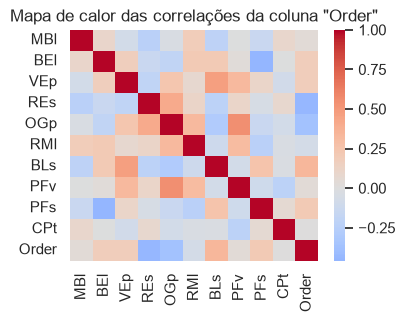

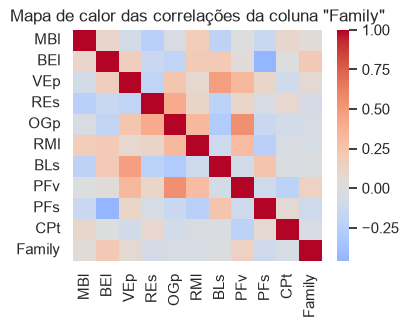

In [ ]:
def draw_heatmap(df, target = ""):
    str_columns = df.select_dtypes(include=["object", "string"])

    for column in str_columns.columns:
        df[column] = LabelEncoder().fit_transform(pd.Series(str_columns[column]))

    correlation = df.corr()
    plt.figure(figsize=(4, 3))
    sns.heatmap(correlation, cmap="coolwarm", center=0)
    plt.title(f"Mapa de calor das correlações da coluna \"{target}\"")
    plt.show()
    return correlation

ord_correlation = draw_heatmap(ord_df, TARGETS[0])
fam_correlation = draw_heatmap(fam_df, TARGETS[1])

=============== Order ===============
Colunas irrelevantes: []
Amostras atualizadas:


,MBl,BEl,VEp,REs,OGp,RMl,BLs,PFv,PFs,CPt
0,4.9,3.570231,0.609119,0.450424,0.449641,0.415711,0.653850,0.566776,0.228959,1.666948
1,51.0,4.209456,0.603144,0.292672,0.219525,0.184593,0.541878,0.209731,0.185695,2.901687
2,82.0,3.105530,0.441475,0.411882,0.269645,0.543565,0.398438,0.250000,0.193187,2.312547


Uso de memória das amostras filtradas: 31.53 KB



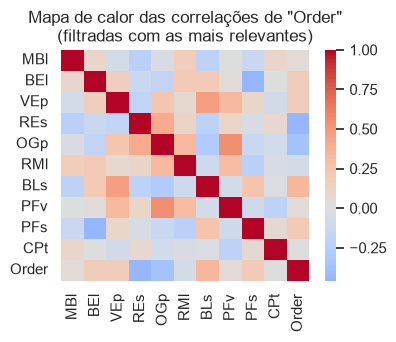

=============== Family ===============
Colunas irrelevantes: []
Amostras atualizadas:


,MBl,BEl,VEp,REs,OGp,RMl,BLs,PFv,PFs,CPt
0,4.9,3.570231,0.609119,0.450424,0.449641,0.415711,0.653850,0.566776,0.228959,1.666948
1,82.0,3.105530,0.441475,0.411882,0.269645,0.543565,0.398438,0.250000,0.193187,2.312547
2,65.0,4.694873,0.454828,0.264794,0.000000,0.685132,0.555463,0.233216,0.179713,2.800205


Uso de memória das amostras filtradas: 24.13 KB



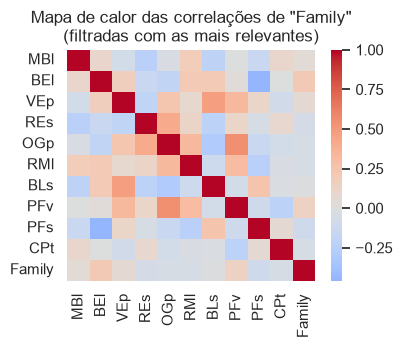

In [ ]:
CORRELATION_THRESHOLD = 0.2

def drop_irrelevant_cols(df, x, correlation, target):
    irrelevant_cols = set()
    for column_name in correlation.drop(columns=[target]).columns:
        column = correlation[column_name].drop(column_name)
        direct_correlation = column[column >= CORRELATION_THRESHOLD]
        inverse_correlation = column[column <= -CORRELATION_THRESHOLD]
        if len(direct_correlation) + len(inverse_correlation) == 0: irrelevant_cols.add(column_name)
    print("=" * 15, target, "=" * 15)
    print("Colunas irrelevantes:", list(irrelevant_cols))
    
    correlation = df.drop(columns=irrelevant_cols).corr()
    plt.figure(figsize=(4, 3))
    sns.heatmap(correlation, annot=False, cmap="coolwarm", center=0)
    plt.title(f"Mapa de calor das correlações de \"{target}\"\n(filtradas com as mais relevantes)")

    updated_x = x.drop(columns=irrelevant_cols)
    
    print("Amostras atualizadas:")
    display(updated_x.head(3))
    print(f"Uso de memória das amostras filtradas: {(updated_x.memory_usage() / 1000).sum():.2f} KB\n")
    plt.show()
    
    return updated_x

x_ord = drop_irrelevant_cols(ord_df, x_ord, ord_correlation, TARGETS[0])
x_fam = drop_irrelevant_cols(fam_df, x_fam, fam_correlation, TARGETS[1])

del ord_correlation, fam_correlation, CORRELATION_THRESHOLD

In [ ]:
TEST_SIZE = 0.2

def split_samples(x, y, target):
    x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

    print(f"Dataset da coluna \"{target}\"")
    print("Treino:", x_train.shape, f"Uso de memória: {(x_train.memory_usage() / 1000).sum():.2f} KB")
    print("Teste:", x_test.shape, f"Uso de memória: {x_test.memory_usage().sum() / 1000:.2f} KB")
    print(f"\nImpacto de memória definitivo: {(x_train.memory_usage().sum() + x_test.memory_usage().sum()) / 1000:.2f} KB")

    return x_train, x_test, y_train, y_test

x_train_ord, x_test_ord, y_train_ord, y_test_ord = split_samples(x_ord, y_ord, TARGETS[0])
print("=" * 50)
x_train_fam, x_test_fam, y_train_fam, y_test_fam = split_samples(x_fam, y_fam, TARGETS[1])

Dataset da coluna "Order"
Treino: (628, 10) Uso de memória: 30.14 KB
Teste: (157, 10) Uso de memória: 7.54 KB

Impacto de memória definitivo: 37.68 KB
Dataset da coluna "Family"
Treino: (480, 10) Uso de memória: 23.04 KB
Teste: (120, 10) Uso de memória: 5.76 KB

Impacto de memória definitivo: 28.80 KB


In [ ]:
CV_SPLITS = 5
N_JOBS = 1

params_dict = {
    'svm linear': (SVC(kernel="linear"), {
        'clf__C': [100, 700, 1000, 1500],
        'clf__class_weight': [None, 'balanced'],
    }),
    'svm rbf': (SVC(kernel="rbf"), {
        'clf__C': [10, 100],
        'clf__gamma': ['auto', 'scale', 0.01, 0.1, 1, 10],
        'clf__class_weight': [None]
    }),
    'svm poly': (SVC(kernel="poly"), {
        'clf__C': [1, 10],
        'clf__gamma': [1, 10],
        'clf__coef0': [0, 1],
        'clf__class_weight': [None, 'balanced']
    }),
    'svm sigmoid': (SVC(kernel="sigmoid"), {
        'clf__C': [1, 10],
        'clf__gamma': ['auto', 'scale', 0.001, 0.01, 0.1],
        'clf__coef0': [0, 1],
        'clf__class_weight': [None, 'balanced']
    }),
    'decision tree': (DecisionTreeClassifier(random_state=RANDOM_STATE), {
        'clf__criterion': ['gini', 'entropy'],
        'clf__max_depth': [None, 10, 20, 40],
        'clf__min_samples_split': [2, 5, 10],
        'clf__min_samples_leaf': [1, 2, 4],
        'clf__max_features': [None, 'sqrt', 'log2'],
        # 'clf__class_weight': [None, 'balanced']  # enable if imbalance is severe
    }),
    "random_forest": (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=N_JOBS), {
        'clf__class_weight': [None, 'balanced'],
        'clf__max_depth': [None, 10, 20],
        'clf__max_features': ['sqrt', 'log2'],
        'clf__min_samples_leaf': [1, 2],
        'clf__min_samples_split': [2, 5],
        'clf__n_estimators': [200, 500],
    }),
    "xgboost": (XGBClassifier(
        objective='binary:logistic',
        eval_metric='mlogloss',
        tree_method='hist',   # fast and Kaggle-friendly
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS,
    ), {
        'clf__colsample_bytree': [0.5, 1.0],
        'clf__learning_rate': [0.1, 0.5, 1],
        'clf__max_depth': [6, 8],
        'clf__n_estimators': [200, 500],
        'clf__reg_lambda': [0.1, 0.5],
        'clf__subsample': [1.0],
    }),
}

iterations_df = pd.DataFrame()
for clf, (_, values) in params_dict.items():
    combinations = CV_SPLITS
    for value in values.values():
        combinations *= len(value)
    iterations_df[clf.upper()] = [combinations]

iterations_df["Total Fam + Ord"] = iterations_df.values.sum() * 2
iterations_df = iterations_df.transpose()
iterations_df.columns = ["Iterações"]
iterations_df["Cálculos Ord"] = iterations_df["Iterações"] * len(x_train_ord)
iterations_df["Cálculos Fam"] = iterations_df["Iterações"] * len(x_train_fam)
iterations_df

,Iterações,Cálculos Ord,Cálculos Fam
RANDOM_FOREST,480,301440,230400
XGBOOST,240,150720,115200
Total Fam + Ord,1440,904320,691200


In [ ]:
def train_predict_models(x, x_train, x_test, y_train, target):
    preprocessing = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(copy=False), list(x.select_dtypes(include="number").columns)),
        ],
    )

    cv = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)
    results, predictions, fitted, cv_tables = [], {}, {}, {}

    for classifier, (clf, param_grid) in params_dict.items():
        print('=' * 15, f'Executando {classifier.upper()} para {target.upper()}...', '=' * 15)

        pipeline = Pipeline([
            ('prep', preprocessing),
            ('clf', clf),
        ], verbose=True)
        search = GridSearchCV(pipeline, param_grid=param_grid, cv=cv, scoring='accuracy', n_jobs=N_JOBS, refit=True, verbose=3)

        label_encoder = LabelEncoder().fit(y_train)
        y_train_enc = label_encoder.transform(y_train)

        start = time.monotonic()
        search.fit(x_train, y_train_enc)
        elapsed = time.monotonic() - start
        print(f'Modelo treinado em {elapsed:.2f}s')

        y_pred_enc = search.best_estimator_.predict(x_test)
        y_pred = label_encoder.inverse_transform(y_pred_enc)

        fitted[classifier] = search
        predictions[classifier] = y_pred
        cv_tables[classifier] = pd.DataFrame(search.cv_results_).sort_values(by=['rank_test_score']).drop(columns=['params', 'std_test_score', 'std_fit_time', 'std_score_time', 'mean_fit_time', 'mean_score_time'])
        results.append({
            'classifier': classifier,
            'cv_best_score': float(search.best_score_),
            'cv_accuracy': float(cv_tables[classifier]['mean_test_score'][0]),
        })

        display(
            cv_tables[classifier][:5].transpose(),
            search.best_estimator_,
        )
    return results, predictions, fitted, cv_tables

results_ord, predictions_ord, fitted_ord, cv_tables_ord = train_predict_models(x_ord, x_train_ord, x_test_ord, y_train_ord, TARGETS[0])
results_fam, predictions_fam, fitted_fam, cv_tables_fam = train_predict_models(x_fam, x_train_fam, x_test_fam, y_train_fam, TARGETS[1])

=============== Executando RANDOM_FOREST para ORDER... ===============
Fitting 5 folds for each of 96 candidates, totalling 480 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.1s


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.


building tree 12 of 500building tree 1 of 500

building tree 6 of 500
building tree 5 of 500
building tree 11 of 500
building tree 9 of 500
building tree 7 of 500
building tree 8 of 500
building tree 4 of 500
building tree 3 of 500
building tree 10 of 500
building tree 2 of 500
building tree 13 of 500
building tree 14 of 500
building tree 15 of 500
building tree 16 of 500
building tree 17 of 500
building tree 18 of 500
building tree 19 of 500
building tree 20 of 500
building tree 21 of 500
building tree 22 of 500
building tree 23 of 500
building tree 24 of 500
building tree 25 of 500
building tree 26 of 500
building tree 27 of 500
building tree 28 of 500
building tree 29 of 500
building tree 30 of 500
building tree 31 of 500
building tree 32 of 500
building tree 33 of 500
building tree 34 of 500
building tree 35 of 500
building tree 36 of 500
building tree 37 of 500
building tree 38 of 500
building tree 39 of 500
building tree 40 of 500
building tree 41 of 500
building tree 42 of 500
b

[Parallel(n_jobs=-1)]: Done   1 tasks      | elapsed:    0.4s
[Parallel(n_jobs=-1)]: Done   8 tasks      | elapsed:    0.4s
[Parallel(n_jobs=-1)]: Done  17 tasks      | elapsed:    0.5s
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    0.5s
[Parallel(n_jobs=-1)]: Done  37 tasks      | elapsed:    0.5s
[Parallel(n_jobs=-1)]: Done  48 tasks      | elapsed:    0.5s
[Parallel(n_jobs=-1)]: Done  61 tasks      | elapsed:    0.6s
[Parallel(n_jobs=-1)]: Done  74 tasks      | elapsed:    0.6s
[Parallel(n_jobs=-1)]: Done  89 tasks      | elapsed:    0.6s


building tree 92 of 500
building tree 93 of 500
building tree 94 of 500
building tree 95 of 500
building tree 96 of 500
building tree 97 of 500
building tree 98 of 500
building tree 99 of 500
building tree 100 of 500
building tree 101 of 500
building tree 102 of 500
building tree 103 of 500
building tree 104 of 500
building tree 105 of 500
building tree 106 of 500
building tree 107 of 500
building tree 108 of 500
building tree 109 of 500
building tree 110 of 500
building tree 111 of 500
building tree 112 of 500
building tree 113 of 500
building tree 114 of 500
building tree 115 of 500
building tree 116 of 500
building tree 117 of 500
building tree 118 of 500
building tree 119 of 500
building tree 120 of 500
building tree 121 of 500
building tree 122 of 500
building tree 123 of 500
building tree 124 of 500
building tree 125 of 500
building tree 126 of 500
building tree 127 of 500
building tree 128 of 500
building tree 129 of 500
building tree 130 of 500
building tree 131 of 500
building

[Parallel(n_jobs=-1)]: Done 104 tasks      | elapsed:    0.7s
[Parallel(n_jobs=-1)]: Done 121 tasks      | elapsed:    0.7s
[Parallel(n_jobs=-1)]: Done 138 tasks      | elapsed:    0.8s
[Parallel(n_jobs=-1)]: Done 157 tasks      | elapsed:    0.8s
[Parallel(n_jobs=-1)]: Done 176 tasks      | elapsed:    0.9s


... (11 outputs left out)

,13,7,28,10,6
param_clf__colsample_bytree,0.500000,0.500000,1.000000,0.500000,0.500000
param_clf__learning_rate,0.500000,0.100000,0.100000,0.500000,0.100000
param_clf__max_depth,8.000000,8.000000,8.000000,6.000000,8.000000
param_clf__n_estimators,200.000000,500.000000,200.000000,500.000000,500.000000
param_clf__reg_lambda,0.500000,0.500000,0.100000,0.100000,0.100000
param_clf__subsample,1.000000,1.000000,1.000000,1.000000,1.000000
split0_test_score,0.658730,0.698413,0.674603,0.666667,0.682540
split1_test_score,0.738095,0.722222,0.706349,0.730159,0.706349
split2_test_score,0.817460,0.785714,0.761905,0.777778,0.793651
split3_test_score,0.720000,0.736000,0.744000,0.728000,0.728000


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",True
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](7,)","[0,1,2,...,4,5,6]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['MBl','BEl','VEp',...,'PFv','PFs','CPt']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in

=============== Executando RANDOM_FOREST para FAMILY... ===============
Fitting 5 folds for each of 96 candidates, totalling 480 fits


KeyboardInterrupt: 

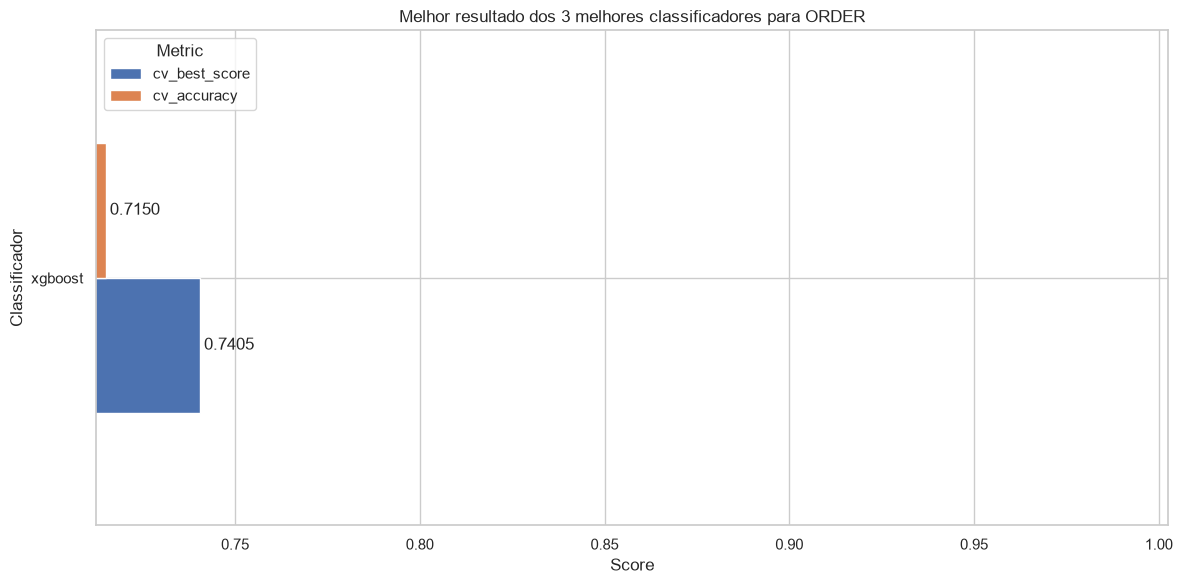

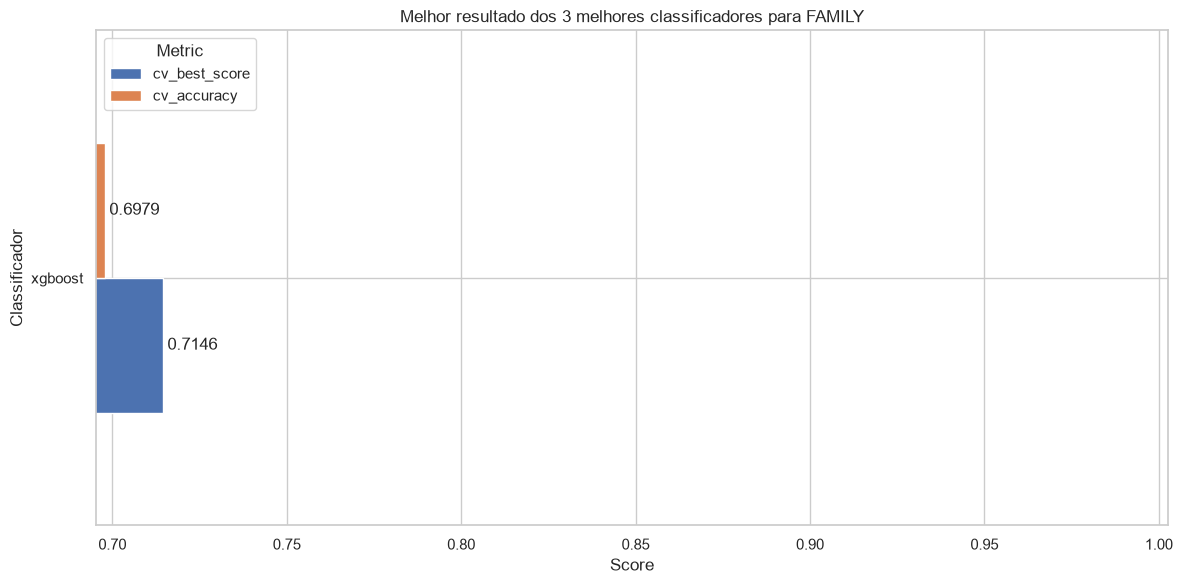

In [ ]:
def plot_results(results, target):
  results_df = pd.DataFrame(results)

  plot_data = results_df.set_index('classifier')[results_df.columns[1:]].sort_values(by=['cv_accuracy', 'cv_best_score'])[-3:]

  ax = plot_data.plot(kind='barh', figsize=(12,6), width=0.6)

  ax.set(
    title=f"Melhor resultado dos 3 melhores classificadores para {target.upper()}",
    xlabel="Score",
    ylabel="Classificador",
    xlim=(plot_data.min().min() - 0.0025, 1.0025),
  )
  ax.legend(loc='upper left', ncols=1, title='Metric')

  for bars in ax.containers:
      ax.bar_label(bars, fmt='%.4f', padding=3)

  plt.tight_layout()
  plt.show()

plot_results(results_ord, TARGETS[0])
plot_results(results_fam, TARGETS[1])

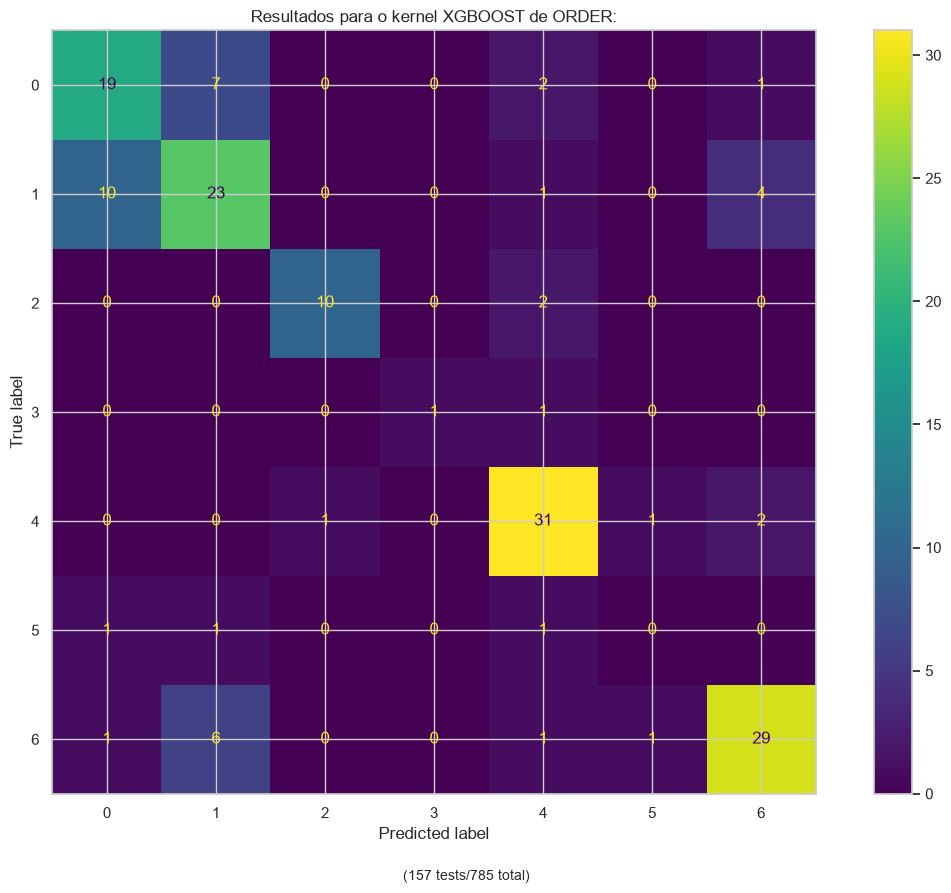

Exception ignored on calling weakref callback <function WeakKeyDictionary.__init__.<locals>.remove at 0x000002801FDFE6C0>:
Traceback (most recent call last):
  File "c:\Users\estagiarioti.e01\AppData\Local\Python\pythoncore-3.14-64\Lib\weakref.py", line 312, in remove
    self = selfref()
KeyboardInterrupt: 


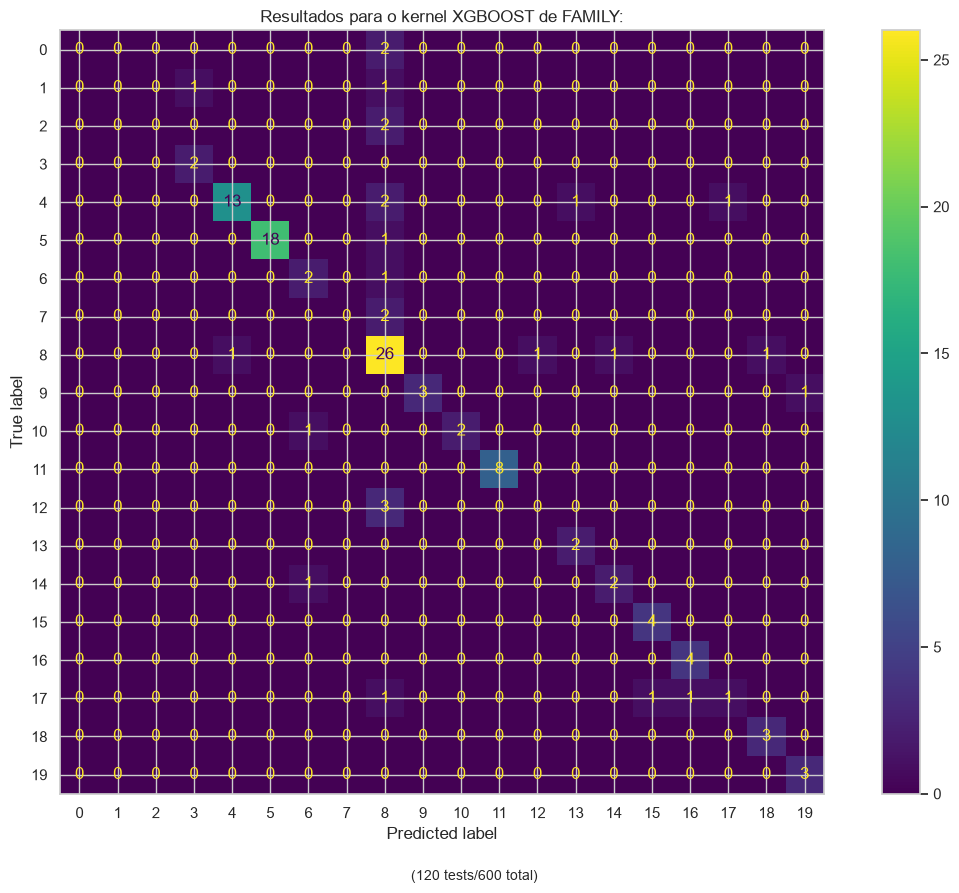

In [ ]:
def plot_confusion_matrices(predictions, x, x_test, y_test, target):
    for svm_type, prediction in predictions.items():
        cm_disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, prediction)).plot()
        cm_disp.ax_.set_title(f'Resultados para o kernel {svm_type.upper()} de {target.upper()}:')
        cm_disp.figure_.supxlabel(f"({len(x_test)} tests/{len(x)} total)", size=10)
        cm_disp.figure_.set_figwidth(12)
        cm_disp.figure_.set_figheight(9)

    plt.tight_layout()
    plt.show()

plot_confusion_matrices(predictions_ord, x_ord, x_test_ord, y_test_ord, TARGETS[0])
plot_confusion_matrices(predictions_fam, x_fam, x_test_fam, y_test_fam, TARGETS[1])

In [ ]:
def display_worst_classifiers(cv_tables, target):
    for clf_type, table in cv_tables.items():
        print(f'As piores performances de {clf_type.upper()} para {target.upper()}:')
        display(table.sort_values(by=['rank_test_score'],ascending=False).head(7).transpose())

display_worst_classifiers(cv_tables_ord, TARGETS[0])
print("=" * 70)
display_worst_classifiers(cv_tables_fam, TARGETS[1])

As piores performances de SVM LINEAR para ORDER:


,5,7,3,1,6,2,4
param_clf__C,1000,1500,700,100,1500,700,1000
param_clf__class_weight,balanced,balanced,balanced,balanced,NaN,NaN,NaN
split0_test_score,0.634921,0.634921,0.634921,0.642857,0.626984,0.626984,0.626984
split1_test_score,0.68254,0.68254,0.68254,0.68254,0.674603,0.674603,0.674603
split2_test_score,0.690476,0.690476,0.690476,0.698413,0.722222,0.722222,0.722222
split3_test_score,0.72,0.72,0.72,0.728,0.704,0.704,0.704
split4_test_score,0.592,0.592,0.592,0.592,0.664,0.672,0.672
mean_test_score,0.663987,0.663987,0.663987,0.668762,0.678362,0.679962,0.679962
rank_test_score,6,6,6,5,4,2,2


As piores performances de SVM RBF para ORDER:


,11,5,4,10,9,6,7
param_clf__C,100,10,10,100,100,100,100
param_clf__class_weight,None,None,None,None,None,None,None
param_clf__gamma,10,10,1,1,0.1,auto,scale
split0_test_score,0.246032,0.246032,0.619048,0.619048,0.611111,0.611111,0.611111
split1_test_score,0.31746,0.31746,0.666667,0.666667,0.746032,0.746032,0.746032
split2_test_score,0.253968,0.253968,0.603175,0.603175,0.738095,0.738095,0.738095
split3_test_score,0.272,0.272,0.616,0.616,0.728,0.728,0.728
split4_test_score,0.24,0.24,0.68,0.68,0.672,0.672,0.672
mean_test_score,0.265892,0.265892,0.636978,0.636978,0.699048,0.699048,0.699048
rank_test_score,11,11,9,9,6,6,6


As piores performances de SVM POLY para ORDER:


,4,7,3,11,15,5,9
param_clf__C,1,1,1,10,10,1,10
param_clf__class_weight,balanced,balanced,NaN,NaN,balanced,balanced,NaN
param_clf__coef0,0,1,1,1,1,0,0
param_clf__gamma,1,10,10,10,10,10,10
split0_test_score,0.579365,0.563492,0.563492,0.563492,0.563492,0.579365,0.579365
split1_test_score,0.68254,0.65873,0.65873,0.65873,0.65873,0.666667,0.666667
split2_test_score,0.626984,0.642857,0.642857,0.642857,0.642857,0.65873,0.65873
split3_test_score,0.608,0.64,0.64,0.64,0.64,0.616,0.616
split4_test_score,0.592,0.6,0.6,0.6,0.6,0.6,0.6
mean_test_score,0.617778,0.621016,0.621016,0.621016,0.621016,0.624152,0.624152


... (18 outputs left out)

As piores performances de RANDOM_FOREST para FAMILY:


,78,70,66,71,79,74,54
param_clf__class_weight,balanced,balanced,balanced,balanced,balanced,balanced,balanced
param_clf__max_depth,10,10,10,10,10,10,None
param_clf__max_features,log2,sqrt,sqrt,sqrt,log2,log2,sqrt
param_clf__min_samples_leaf,2,2,1,2,2,1,2
param_clf__min_samples_split,5,5,5,5,5,5,5
param_clf__n_estimators,200,200,200,500,500,200,200
split0_test_score,0.625,0.625,0.625,0.625,0.625,0.625,0.635417
split1_test_score,0.552083,0.552083,0.5625,0.541667,0.541667,0.5625,0.572917
split2_test_score,0.677083,0.677083,0.697917,0.697917,0.697917,0.697917,0.6875
split3_test_score,0.677083,0.677083,0.697917,0.6875,0.6875,0.697917,0.677083


As piores performances de XGBOOST para FAMILY:


,22,20,18,16,46,44,19
param_clf__colsample_bytree,0.500000,0.500000,0.500000,0.500000,1.000000,1.000000,0.500000
param_clf__learning_rate,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
param_clf__max_depth,8.000000,8.000000,6.000000,6.000000,8.000000,8.000000,6.000000
param_clf__n_estimators,500.000000,200.000000,500.000000,200.000000,500.000000,200.000000,500.000000
param_clf__reg_lambda,0.100000,0.100000,0.100000,0.100000,0.100000,0.100000,0.500000
param_clf__subsample,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
split0_test_score,0.572917,0.572917,0.593750,0.593750,0.583333,0.572917,0.593750
split1_test_score,0.687500,0.697917,0.656250,0.666667,0.614583,0.614583,0.656250
split2_test_score,0.666667,0.666667,0.687500,0.687500,0.729167,0.718750,0.666667
split3_test_score,0.635417,0.635417,0.666667,0.666667,0.666667,0.677083,0.718750
